In [29]:
!pip install -q kagglehub

import glob
import os
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

# Set global visualization styles
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [30]:
# Download the World Happiness Report dataset
dataset_path = kagglehub.dataset_download("jahaidulislam/world-happiness-report-2005-2021")
print(f"Dataset downloaded to: {dataset_path}")
print(f"Files available: {os.listdir(dataset_path)}")

Using Colab cache for faster access to the 'world-happiness-report-2005-2021' dataset.
Dataset downloaded to: /kaggle/input/world-happiness-report-2005-2021
Files available: ['World Happiness Report 2005-2021.csv']


In [6]:
csv_files = glob.glob(os.path.join(dataset_path, "*.csv"))
df = pd.read_csv(csv_files[0])
df.head()

,Country name,Year,Life Ladder,Log GDP per capita,Social support,Healthy life expectancy at birth,Freedom to make life choices,Generosity,Perceptions of corruption,Positive affect,Negative affect,Confidence in national government
0,Afghanistan,2008,3.723590,7.302574,0.450662,50.500000,0.718114,0.173169,0.881686,0.414297,0.258195,0.612072
1,Afghanistan,2009,4.401778,7.472446,0.552308,50.799999,0.678896,0.195469,0.850035,0.481421,0.237092,0.611545
2,Afghanistan,2010,4.758381,7.579183,0.539075,51.099998,0.600127,0.125859,0.706766,0.516907,0.275324,0.299357
3,Afghanistan,2011,3.831719,7.552006,0.521104,51.400002,0.495901,0.167723,0.731109,0.479835,0.267175,0.307386
4,Afghanistan,2012,3.782938,7.637953,0.520637,51.700001,0.530935,0.241247,0.775620,0.613513,0.267919,0.435440


In [7]:
# Standardize column names to snake_case
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

print(f"Dataset dimensions: {df.shape[0]} rows, {df.shape[1]} columns")
print(f"Columns: {df.columns.tolist()}")
print(f"Year range: {df['year'].min()} - {df['year'].max()}\n")
df.info()

Dataset dimensions: 2089 rows, 12 columns
Columns: ['country_name', 'year', 'life_ladder', 'log_gdp_per_capita', 'social_support', 'healthy_life_expectancy_at_birth', 'freedom_to_make_life_choices', 'generosity', 'perceptions_of_corruption', 'positive_affect', 'negative_affect', 'confidence_in_national_government']
Year range: 2005 - 2021

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2089 entries, 0 to 2088
Data columns (total 12 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   country_name                       2089 non-null   object 
 1   year                               2089 non-null   int64  
 2   life_ladder                        2089 non-null   float64
 3   log_gdp_per_capita                 2062 non-null   float64
 4   social_support                     2076 non-null   float64
 5   healthy_life_expectancy_at_birth   2031 non-null   float64
 6   freedom_to_make_life_choices      

In [8]:
missing_count = df.isnull().sum()
missing_percent = (missing_count / len(df) * 100).round(2)

missing_summary = pd.DataFrame({
    "missing_count": missing_count,
    "missing_percent": missing_percent
}).sort_values(by="missing_percent", ascending=False)

missing_summary

,missing_count,missing_percent
confidence_in_national_government,216,10.34
perceptions_of_corruption,113,5.41
generosity,80,3.83
healthy_life_expectancy_at_birth,58,2.78
freedom_to_make_life_choices,32,1.53
log_gdp_per_capita,27,1.29
positive_affect,24,1.15
negative_affect,16,0.77
social_support,13,0.62
life_ladder,0,0.00


In [9]:
# Select numerical feature columns (excluding 'year')
numeric_cols = df.select_dtypes(include="number").columns.drop("year")

# Impute missing values using country-level median, falling back to global median
for col in numeric_cols:
    df[col] = df.groupby("country_name")[col].transform(lambda x: x.fillna(x.median()))
    df[col] = df[col].fillna(df[col].median())

print("Remaining missing values per column:")
print(df.isnull().sum())

Remaining missing values per column:
country_name                         0
year                                 0
life_ladder                          0
log_gdp_per_capita                   0
social_support                       0
healthy_life_expectancy_at_birth     0
freedom_to_make_life_choices         0
generosity                           0
perceptions_of_corruption            0
positive_affect                      0
negative_affect                      0
confidence_in_national_government    0
dtype: int64


In [10]:
# Check for exact row duplicates and country-year duplicates
print(f"Exact duplicate rows: {df.duplicated().sum()}")
print(f"Duplicate country-year pairs: {df.duplicated(subset=['country_name', 'year']).sum()}\n")

# Define South Asian countries and verify their presence in the dataset
south_asia_countries = ["Bangladesh", "India", "Pakistan", "Sri Lanka", "Nepal", "Afghanistan"]
available_sa = [c for c in south_asia_countries if c in df["country_name"].unique()]
print(f"South Asian countries present in dataset: {available_sa}\n")

# Create a regional grouping column
df["region_group"] = np.where(
    df["country_name"].isin(south_asia_countries),
    "South Asia",
    "Rest of World"
)
print(df["region_group"].value_counts())

Exact duplicate rows: 0
Duplicate country-year pairs: 0

South Asian countries present in dataset: ['Bangladesh', 'India', 'Pakistan', 'Sri Lanka', 'Nepal', 'Afghanistan']

region_group
Rest of World    1998
South Asia         91
Name: count, dtype: int64


count    2089.000000
mean        5.473747
std         1.115567
min         2.178809
25%         4.651972
50%         5.405246
75%         6.294282
max         8.018934
Name: life_ladder, dtype: float64

Skewness: 0.03


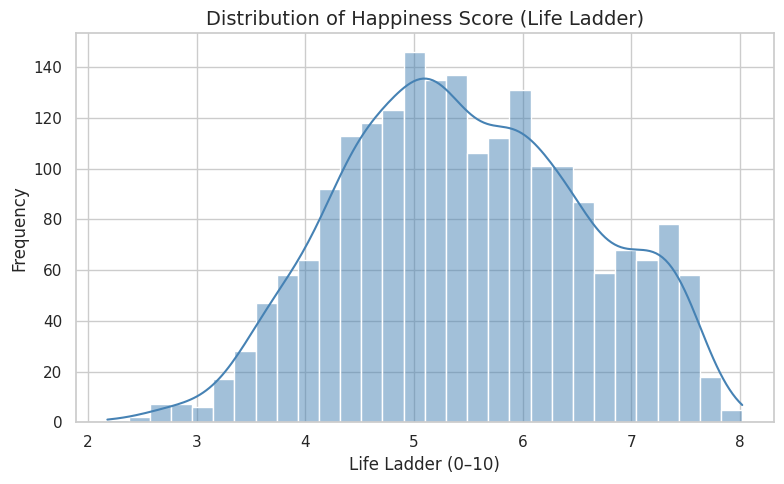

In [11]:
print(df["life_ladder"].describe())
print(f"\nSkewness: {df['life_ladder'].skew():.2f}")

plt.figure(figsize=(8, 5))
sns.histplot(df["life_ladder"], kde=True, bins=30, color="steelblue")
plt.title("Distribution of Happiness Score (Life Ladder)", fontsize=14)
plt.xlabel("Life Ladder (0–10)", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.tight_layout()
plt.show()

Correlation with Life Ladder:
life_ladder                          1.00
log_gdp_per_capita                   0.78
social_support                       0.71
healthy_life_expectancy_at_birth     0.71
freedom_to_make_life_choices         0.53
positive_affect                      0.51
generosity                           0.19
confidence_in_national_government   -0.08
negative_affect                     -0.32
perceptions_of_corruption           -0.44
Name: life_ladder, dtype: float64


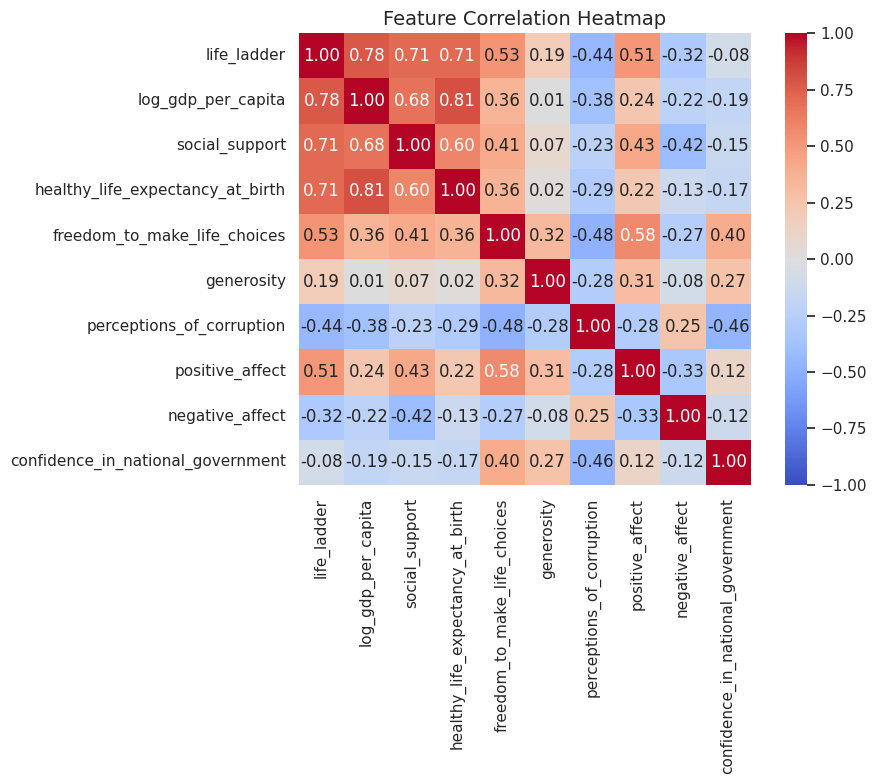

In [12]:
analysis_factors = [
    "life_ladder",
    "log_gdp_per_capita",
    "social_support",
    "healthy_life_expectancy_at_birth",
    "freedom_to_make_life_choices",
    "generosity",
    "perceptions_of_corruption",
    "positive_affect",
    "negative_affect",
    "confidence_in_national_government"
]

correlation_matrix = df[analysis_factors].corr()
print("Correlation with Life Ladder:")
print(correlation_matrix["life_ladder"].sort_values(ascending=False).round(2))

plt.figure(figsize=(10, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True
)
plt.title("Feature Correlation Heatmap", fontsize=14)
plt.tight_layout()
plt.show()

Outliers in life_ladder: 1


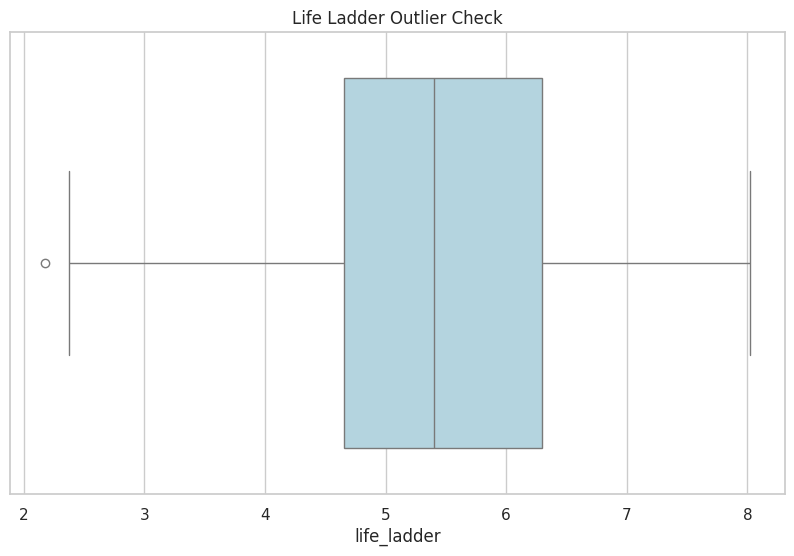

In [24]:
Q1, Q3 = df["life_ladder"].quantile([0.25, 0.75])
IQR = Q3 - Q1
outliers = df[(df.life_ladder < Q1 - 1.5*IQR) | (df.life_ladder > Q3 + 1.5*IQR)]
print(f"Outliers in life_ladder: {len(outliers)}")

sns.boxplot(x=df["life_ladder"], color="lightblue")
plt.title("Life Ladder Outlier Check")
plt.show()

Regional Summary Statistics:
              life_ladder        log_gdp_per_capita        social_support  \
                     mean median               mean median           mean   
region_group                                                                
Rest of World        5.52   5.47               9.43   9.52           0.82   
South Asia           4.52   4.56               8.33   8.28           0.65   

                      
              median  
region_group          
Rest of World   0.84  
South Asia      0.62  

Welch's T-Test (South Asia vs. Rest of World):
T-statistic: -12.972, P-value: 4.6551e-24
Mann-Whitney U p-value: 7.5203e-18


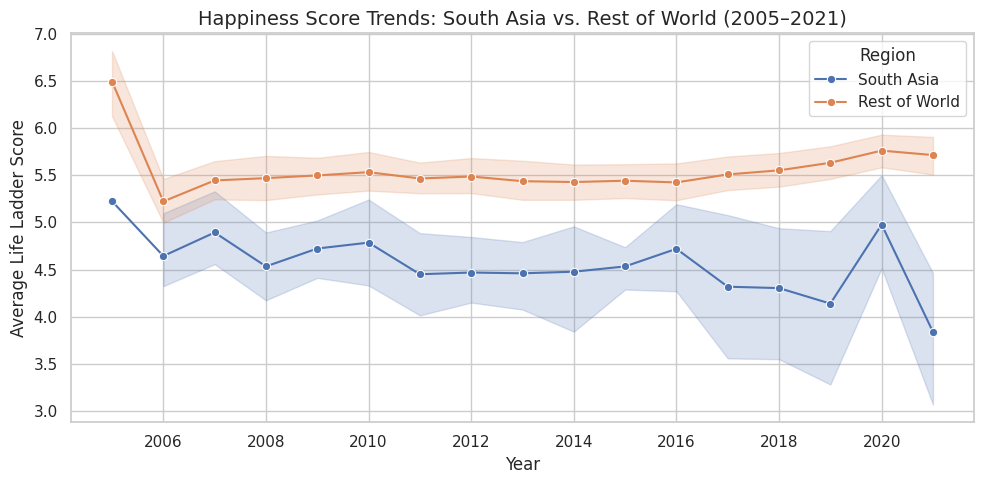

In [15]:
# Compare mean and median metrics between South Asia and the Rest of the World
regional_summary = df.groupby("region_group")[["life_ladder", "log_gdp_per_capita", "social_support"]].agg(["mean", "median"])
print("Regional Summary Statistics:")
print(regional_summary.round(2))

# Perform an independent two-sample t-test (Welch's t-test) on Life Ladder scores
sa_scores = df[df["region_group"] == "South Asia"]["life_ladder"]
row_scores = df[df["region_group"] == "Rest of World"]["life_ladder"]

t_stat, p_val = stats.ttest_ind(sa_scores, row_scores, equal_var=False)
print(f"\nWelch's T-Test (South Asia vs. Rest of World):")
print(f"T-statistic: {t_stat:.3f}, P-value: {p_val:.4e}")
u_stat, p_mw = stats.mannwhitneyu(sa_scores, row_scores, alternative="two-sided")
print(f"Mann-Whitney U p-value: {p_mw:.4e}")
# Visualize the regional comparison over time
plt.figure(figsize=(10, 5))
sns.lineplot(data=df, x="year", y="life_ladder", hue="region_group", marker="o")
plt.title("Happiness Score Trends: South Asia vs. Rest of World (2005–2021)", fontsize=14)
plt.xlabel("Year", fontsize=12)
plt.ylabel("Average Life Ladder Score", fontsize=12)
plt.legend(title="Region")
plt.tight_layout()
plt.show()

South Asian countries included: ['Bangladesh', 'India', 'Nepal', 'Pakistan', 'Sri Lanka']
region_group  Rest of World  South Asia
year                                   
2017                  5.718       4.651
2018                  5.781       4.627
2019                  5.789       4.494
2020                  5.746       4.978


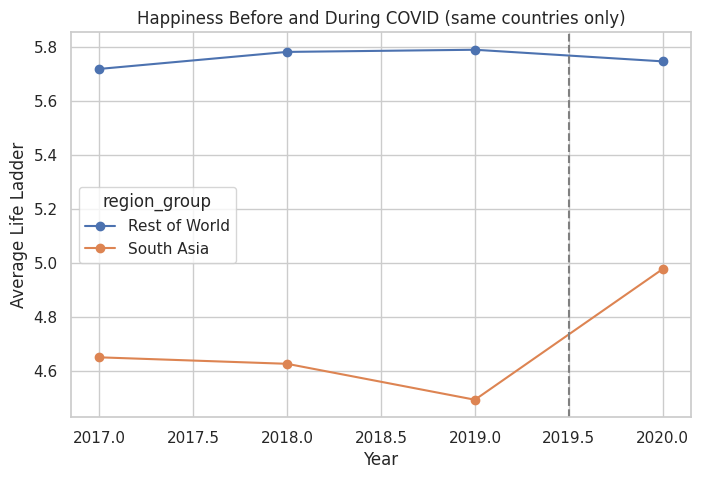

In [17]:
years = range(2017, 2021)   # 2017–2020 so Bangladesh is included (its data ends in 2020)
counts = df[df["year"].isin(years)].groupby("country_name")["year"].nunique()
full_countries = counts[counts == len(years)].index

covid_df = df[df["country_name"].isin(full_countries) & df["year"].isin(years)]
print("South Asian countries included:", sorted(covid_df[covid_df.region_group=="South Asia"]["country_name"].unique()))

covid = covid_df.groupby(["year", "region_group"])["life_ladder"].mean().unstack().round(3)
print(covid)

covid.plot(marker="o", figsize=(8, 5))
plt.axvline(2019.5, color="gray", linestyle="--")
plt.title("Happiness Before and During COVID (same countries only)")
plt.ylabel("Average Life Ladder")
plt.xlabel("Year")
plt.show()

Average Metrics Across South Asian Countries (2005–2021):
              life_ladder  log_gdp_per_capita  social_support  \
country_name                                                    
Pakistan             5.16                8.34            0.57   
Nepal                4.77                8.03            0.78   
Bangladesh           4.75                8.13            0.61   
India                4.42                8.51            0.60   
Sri Lanka            4.33                9.26            0.83   
Afghanistan          3.51                7.59            0.50   

              freedom_to_make_life_choices  
country_name                                
Pakistan                              0.55  
Nepal                                 0.69  
Bangladesh                            0.75  
India                                 0.80  
Sri Lanka                             0.81  
Afghanistan                           0.51  


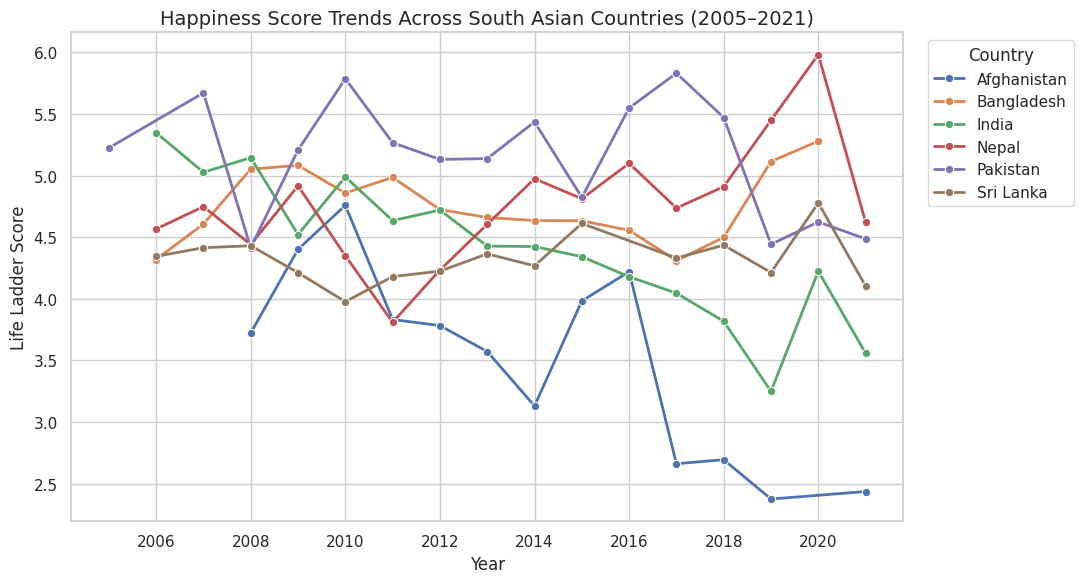

In [34]:
# Filter dataset for South Asian countries
sa_df = df[df["region_group"] == "South Asia"]

# Summary statistics per South Asian country (2005–2021)
sa_country_summary = (
    sa_df.groupby("country_name")[["life_ladder", "log_gdp_per_capita", "social_support", "freedom_to_make_life_choices"]]
    .mean()
    .sort_values(by="life_ladder", ascending=False)
    .round(2)
)
print("Average Metrics Across South Asian Countries (2005–2021):")
print(sa_country_summary)

# Plot individual country trends over time
plt.figure(figsize=(11, 6))
sns.lineplot(
    data=sa_df,
    x="year",
    y="life_ladder",
    hue="country_name",
    marker="o",
    linewidth=2
)
plt.title("Happiness Score Trends Across South Asian Countries (2005–2021)", fontsize=14)
plt.xlabel("Year", fontsize=12)
plt.ylabel("Life Ladder Score", fontsize=12)
plt.legend(title="Country", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

Linear Regression R²: 0.783
Linear Regression RMSE: 0.508



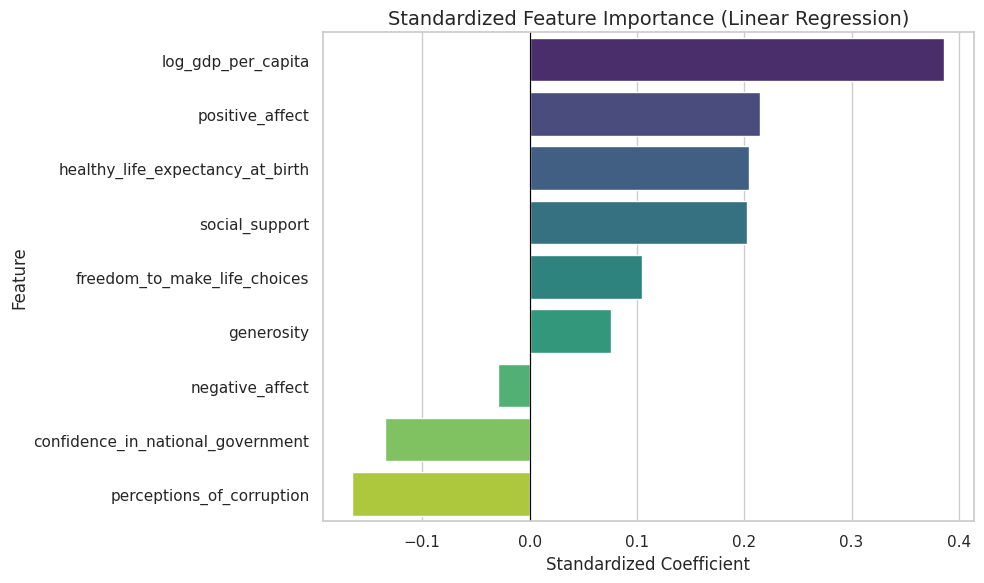

In [18]:
features = [
    "log_gdp_per_capita",
    "social_support",
    "healthy_life_expectancy_at_birth",
    "freedom_to_make_life_choices",
    "generosity",
    "perceptions_of_corruption",
    "positive_affect",
    "negative_affect",
    "confidence_in_national_government"
]

X = df[features]
y = df["life_ladder"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

y_pred_lr = lr_model.predict(X_test_scaled)
print(f"Linear Regression R²: {r2_score(y_test, y_pred_lr):.3f}")
print(f"Linear Regression RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_lr)):.3f}\n")

importance = pd.DataFrame({
    "Feature": features,
    "Standardized_Coefficient": lr_model.coef_
}).sort_values(by="Standardized_Coefficient", ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance,
    x="Standardized_Coefficient",
    y="Feature",
    palette="viridis",
    hue="Feature",
    legend=False
)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Standardized Feature Importance (Linear Regression)", fontsize=14)
plt.xlabel("Standardized Coefficient", fontsize=12)
plt.ylabel("Feature", fontsize=12)
plt.tight_layout()
plt.show()

Random Forest R²: 0.874
Random Forest RMSE: 0.387


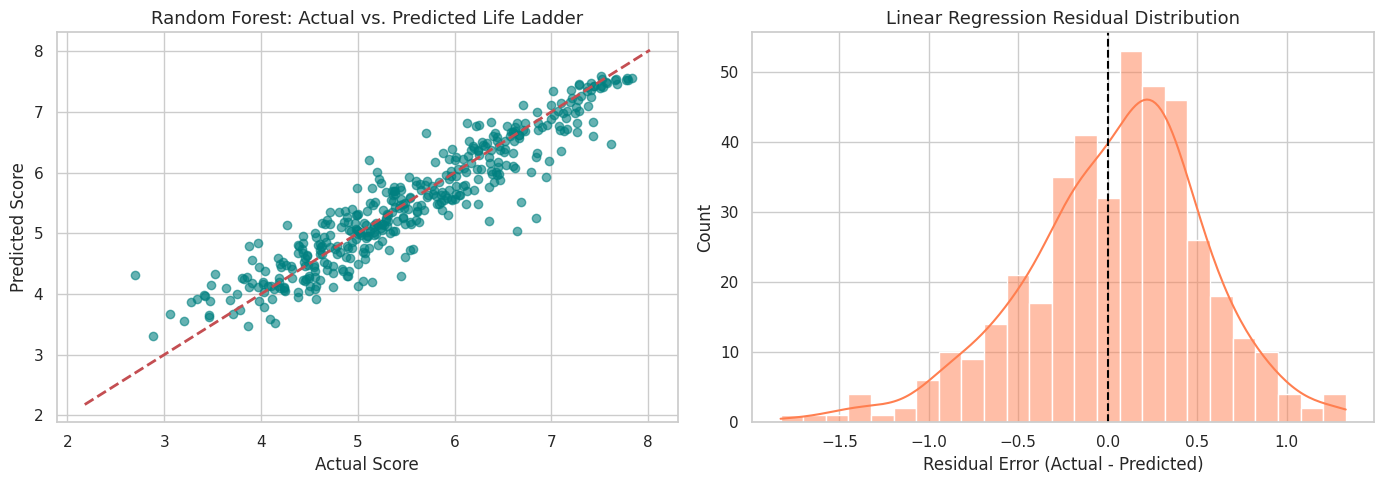

In [19]:
from sklearn.ensemble import RandomForestRegressor

# Train a Random Forest Regressor to capture non-linear relationships
rf_model = RandomForestRegressor(n_estimators=200, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

print(f"Random Forest R²: {r2_score(y_test, y_pred_rf):.3f}")
print(f"Random Forest RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_rf)):.3f}")

# Side-by-side Residual Analysis & Actual vs. Predicted Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Actual vs. Predicted (Random Forest)
axes[0].scatter(y_test, y_pred_rf, alpha=0.6, color="teal")
axes[0].plot([y.min(), y.max()], [y.min(), y.max()], "r--", lw=2)
axes[0].set_title("Random Forest: Actual vs. Predicted Life Ladder", fontsize=13)
axes[0].set_xlabel("Actual Score")
axes[0].set_ylabel("Predicted Score")

# Plot 2: Residuals Distribution (Linear Regression)
residuals = y_test - y_pred_lr
sns.histplot(residuals, kde=True, ax=axes[1], color="coral", bins=25)
axes[1].axvline(0, color="black", linestyle="--")
axes[1].set_title("Linear Regression Residual Distribution", fontsize=13)
axes[1].set_xlabel("Residual Error (Actual - Predicted)")

plt.tight_layout()
plt.show()

In [20]:
# Evaluate how well the global Random Forest model predicts South Asian happiness
# Train WITHOUT South Asia, then test on South Asia
train_mask = df["region_group"] == "Rest of World"
rf_ex = RandomForestRegressor(n_estimators=200, random_state=42)
rf_ex.fit(df.loc[train_mask, features], df.loc[train_mask, "life_ladder"])

sa_df = df[df["region_group"] == "South Asia"]
sa_eval = sa_df[["country_name", "year", "life_ladder"]].copy()
sa_eval["predicted_life_ladder"] = rf_ex.predict(sa_df[features]).round(2)
sa_eval["prediction_error"] = (sa_eval["life_ladder"] - sa_eval["predicted_life_ladder"]).round(2)

print(f"R² on South Asia: {r2_score(sa_eval.life_ladder, sa_eval.predicted_life_ladder):.3f}")
print(sa_eval.groupby("country_name")[["life_ladder","predicted_life_ladder","prediction_error"]].mean().round(2))

R² on South Asia: -0.297
              life_ladder  predicted_life_ladder  prediction_error
country_name                                                      
Afghanistan          3.51                   3.52             -0.01
Bangladesh           4.75                   4.45              0.30
India                4.42                   4.58             -0.17
Nepal                4.77                   4.49              0.28
Pakistan             5.16                   4.30              0.86
Sri Lanka            4.33                   5.50             -1.18


Pearson r: 0.778 | p-value: 0.0
Spearman rho: 0.798 | p-value: 0.0


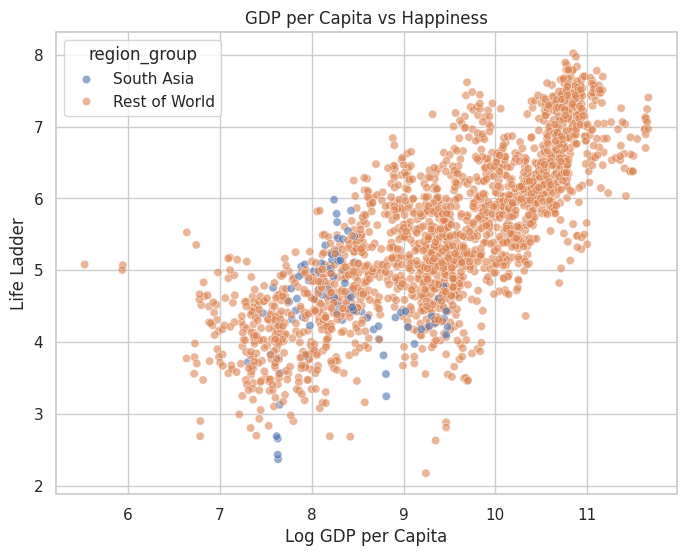

In [21]:
temp = df[["log_gdp_per_capita", "life_ladder"]].dropna()

r, p = stats.pearsonr(temp["log_gdp_per_capita"], temp["life_ladder"])
rho, p_s = stats.spearmanr(temp["log_gdp_per_capita"], temp["life_ladder"])
print("Pearson r:", round(r, 3), "| p-value:", p)
print("Spearman rho:", round(rho, 3), "| p-value:", p_s)

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="log_gdp_per_capita", y="life_ladder",
                hue="region_group", alpha=0.6)
plt.title("GDP per Capita vs Happiness")
plt.xlabel("Log GDP per Capita")
plt.ylabel("Life Ladder")
plt.show()

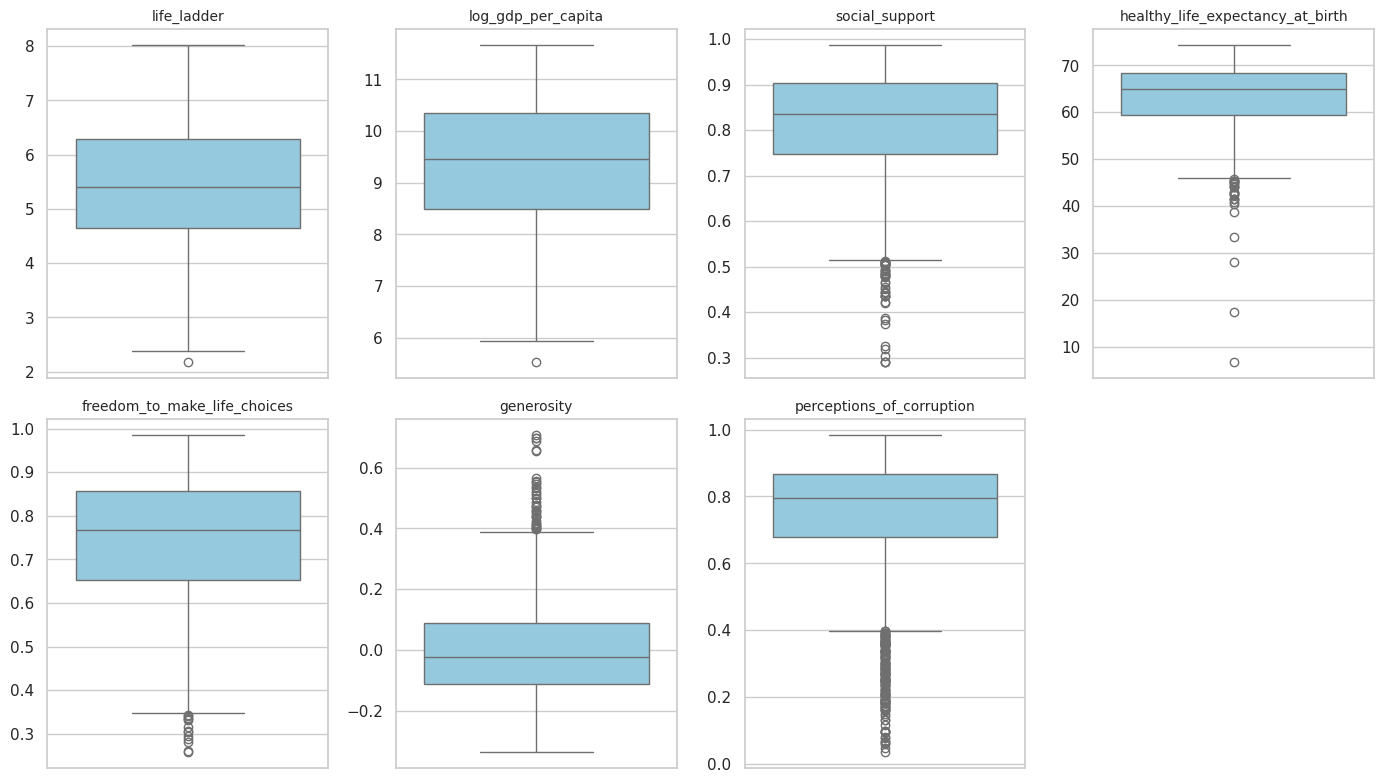

--- Outlier Summary (IQR Method) ---
life_ladder: 1 outliers (range 2.19 to 8.76)
log_gdp_per_capita: 1 outliers (range 5.68 to 13.15)
social_support: 46 outliers (range 0.51 to 1.14)
healthy_life_expectancy_at_birth: 25 outliers (range 45.90 to 81.74)
freedom_to_make_life_choices: 13 outliers (range 0.34 to 1.17)
generosity: 37 outliers (range -0.42 to 0.39)
perceptions_of_corruption: 166 outliers (range 0.40 to 1.15)


In [27]:
# ---- Outlier detection (IQR method) ----
cols_to_check = ["life_ladder", "log_gdp_per_capita", "social_support",
                 "healthy_life_expectancy_at_birth", "freedom_to_make_life_choices",
                 "generosity", "perceptions_of_corruption"]

plt.figure(figsize=(14, 8))
for i, col in enumerate(cols_to_check, 1):
    plt.subplot(2, 4, i)
    sns.boxplot(y=df[col], color="skyblue")
    plt.title(col, fontsize=10)
    plt.ylabel("")
plt.tight_layout()
plt.show()

print("--- Outlier Summary (IQR Method) ---")
for col in cols_to_check:
    Q1, Q3 = df[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    low, high = Q1 - 1.5*IQR, Q3 + 1.5*IQR
    n = ((df[col] < low) | (df[col] > high)).sum()
    print(f"{col}: {n} outliers (range {low:.2f} to {high:.2f})")

In [28]:
# ---- Hypothesis Test 1: GDP vs Happiness (Pearson correlation) ----
# H0: no linear relationship between log GDP per capita and Life Ladder
r, p = stats.pearsonr(df["log_gdp_per_capita"], df["life_ladder"])
print("--- Test 1: GDP vs Happiness ---")
print(f"Pearson r = {r:.3f}, p-value = {p:.2e}")
print("Result:", "Reject H0 (significant relationship)" if p < 0.05 else "Fail to reject H0")

# ---- Hypothesis Test 2: High vs Low social support (Welch t-test) ----
# H0: mean Life Ladder is the same for high and low social support
median_support = df["social_support"].median()
high = df[df["social_support"] >= median_support]["life_ladder"]
low = df[df["social_support"] < median_support]["life_ladder"]
t, p2 = stats.ttest_ind(high, low, equal_var=False)
print("\n--- Test 2: High vs Low Social Support ---")
print(f"Mean (high support): {high.mean():.2f}, Mean (low support): {low.mean():.2f}")
print(f"t = {t:.3f}, p-value = {p2:.2e}")
print("Result:", "Reject H0 (means differ)" if p2 < 0.05 else "Fail to reject H0")

--- Test 1: GDP vs Happiness ---
Pearson r = 0.778, p-value = 0.00e+00
Result: Reject H0 (significant relationship)

--- Test 2: High vs Low Social Support ---
Mean (high support): 6.18, Mean (low support): 4.77
t = 37.516, p-value = 1.99e-235
Result: Reject H0 (means differ)


## Conclusion
- **Main drivers:** GDP per capita, social support and healthy life expectancy are the factors most strongly related to happiness.
- **South Asia:** It scores about one point lower than the rest of the world (4.52 vs 5.52). Only 6 countries are in the data, so this is a descriptive finding.
- **COVID-19:** [one sentence from your COVID table, same countries only]
- **Prediction:** A Random Forest (R² = 0.874) predicts happiness better than linear regression (R² = 0.783).
- **Limitations:** The data has missing values (filled with country medians), small South Asia sample, and correlation is not causation.